# RCA CIE Activity 1: Multiple Linear Regression
**Dataset:** Bengaluru House Data  
**Objective:** Perform preprocessing, manual regression calculations, fit and compare single-feature and multiple-feature models, interpret coefficients, evaluate models, analyze residuals, and check multicollinearity.

> Run cells in order. Review and understand the outputs before submission. Some results may vary if you change the cleaning choices or random seed.

## 1. Import Libraries and Load Dataset
Upload `Bengaluru_House_Data.csv` to Google Colab's Files panel, then run the cell.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

df = pd.read_csv("Bengaluru_House_Data.csv")
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (13320, 9)


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


## 2. Dataset Inspection

In [2]:
print("Columns:", df.columns.tolist())
print("\\nData types:")
display(df.dtypes)
print("\\nDataset information:")
df.info()

Columns: ['area_type', 'availability', 'location', 'size', 'society', 'total_sqft', 'bath', 'balcony', 'price']
\nData types:


,0
area_type,object
availability,object
location,object
size,object
society,object
total_sqft,object
bath,float64
balcony,float64
price,float64


\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB


In [3]:
print("Descriptive statistics:")
display(df.describe(include="all").T)

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
area_type,13320,4,Super built-up Area,8790,NaN,NaN,NaN,NaN,NaN,NaN,NaN
availability,13320,81,Ready To Move,10581,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,13319,1305,Whitefield,540,NaN,NaN,NaN,NaN,NaN,NaN,NaN
size,13304,31,2 BHK,5199,NaN,NaN,NaN,NaN,NaN,NaN,NaN
society,7818,2688,GrrvaGr,80,NaN,NaN,NaN,NaN,NaN,NaN,NaN
total_sqft,13320,2117,1200,843,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bath,13247.0,NaN,NaN,NaN,2.69261,1.341458,1.0,2.0,2.0,3.0,40.0
balcony,12711.0,NaN,NaN,NaN,1.584376,0.817263,0.0,1.0,2.0,2.0,3.0
price,13320.0,NaN,NaN,NaN,112.565627,148.971674,8.0,50.0,72.0,120.0,3600.0


In [4]:
print("Missing values:")
display(df.isnull().sum().to_frame("Missing Values"))
print("\\nMissing percentage:")
display((df.isnull().mean() * 100).round(2).to_frame("Missing Percentage"))
print("\\nDuplicate rows:", df.duplicated().sum())

Missing values:


,Missing Values
area_type,0
availability,0
location,1
size,16
society,5502
total_sqft,0
bath,73
balcony,609
price,0


\nMissing percentage:


,Missing Percentage
area_type,0.00
availability,0.00
location,0.01
size,0.12
society,41.31
total_sqft,0.00
bath,0.55
balcony,4.57
price,0.00


\nDuplicate rows: 529


## 3. Preprocessing
We use numerical predictors: total square feet, bedrooms, bathrooms, and balconies. We drop `society` because it has many missing values and is not part of the selected model. The location and categorical amenity columns are not used in this first numerical regression model.

In [22]:
import re
import numpy as np
import pandas as pd

# Convert size strings like '3 BHK' or '2 Bedroom' to bedroom count
def extract_bedrooms(value):
    if pd.isna(value):
        return np.nan
    match = re.search(r'\d+(?:\.\d+)?', str(value))
    return float(match.group()) if match else np.nan

df["bedrooms"] = df["size"].apply(extract_bedrooms)

# Convert total_sqft strings into numeric square feet.
# Ranges are represented by their midpoint. Recognized units are converted to sqft.
def sqft_to_number(value):
    if pd.isna(value):
        return np.nan
    text = str(value).strip().lower().replace(",", "")

    # Handle ranges such as 1200 - 1500 by taking the midpoint
    range_match = re.search(r'(\d+(?:\.\d+)?)\s*-\s*(\d+(?:\.\d+)?)', text)
    if range_match:
        return (float(range_match.group(1)) + float(range_match.group(2))) / 2

    # Handle units
    number_match = re.search(r'\d+(?:\.\d+)?', text)
    if not number_match:
        return np.nan
    number = float(number_match.group())

    if "sq. meter" in text or "sqm" in text or "square meter" in text:
        return number * 10.7639
    elif "sq. yard" in text or "sq yard" in text or "square yard" in text:
        return number * 9
    elif "acre" in text:
        return number * 43560
    elif "cent" in text:
        return number * 435.6
    else:
        return number  # assume already in square feet

df["total_sqft_clean"] = df["total_sqft"].apply(sqft_to_number)

print("After conversions:")
display(df[["total_sqft", "total_sqft_clean", "size", "bedrooms"]].head(10))
print("Conversion missing values:", df["total_sqft_clean"].isna().sum())

After conversions:


,total_sqft,total_sqft_clean,size,bedrooms
0,1056,1056.0,2 BHK,2.0
1,2600,2600.0,4 Bedroom,4.0
2,1440,1440.0,3 BHK,3.0
3,1521,1521.0,3 BHK,3.0
4,1200,1200.0,2 BHK,2.0
5,1170,1170.0,2 BHK,2.0
6,2732,2732.0,4 BHK,4.0
7,3300,3300.0,4 BHK,4.0
8,1310,1310.0,3 BHK,3.0
9,1020,1020.0,6 Bedroom,6.0


Conversion missing values: 0


In [24]:
# Keep plausible house area range and remove duplicates
df_clean = df.copy()

# Remove rows with invalid/non-positive area, and very extreme area values.
# This threshold is a practical screening choice and should be acknowledged.
df_clean = df_clean[df_clean["total_sqft_clean"].between(100, 10000)]
df_clean = df_clean.drop_duplicates()

print("Shape before filtering:", df.shape)
print("Shape after area filter + duplicate removal:", df_clean.shape)
print("Remaining duplicates:", df_clean.duplicated().sum())

Shape before filtering: (13320, 11)
Shape after area filter + duplicate removal: (12743, 11)
Remaining duplicates: 0


In [25]:
# Missing-value handling for selected model columns
selected_cols = ["total_sqft_clean", "bedrooms", "bath", "balcony", "price"]

print("Missing values in selected columns before handling:")
display(df_clean[selected_cols].isnull().sum())

# Median imputation for predictor columns only.
# Target price has no missing values in this dataset; rows with missing target are dropped if present.
for col in ["total_sqft_clean", "bedrooms", "bath", "balcony"]:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

df_clean = df_clean.dropna(subset=["price"])
df_model = df_clean[selected_cols].copy()

print("Missing values after handling:")
display(df_model.isnull().sum())
print("Final modeling dataset shape:", df_model.shape)
display(df_model.head())

Missing values in selected columns before handling:


,0
total_sqft_clean,0
bedrooms,16
bath,73
balcony,600
price,0


Missing values after handling:


,0
total_sqft_clean,0
bedrooms,0
bath,0
balcony,0
price,0


Final modeling dataset shape: (12743, 5)


,total_sqft_clean,bedrooms,bath,balcony,price
0,1056.0,2.0,2.0,1.0,39.07
1,2600.0,4.0,5.0,3.0,120.00
2,1440.0,3.0,2.0,3.0,62.00
3,1521.0,3.0,3.0,1.0,95.00
4,1200.0,2.0,2.0,1.0,51.00


### Preprocessing decisions
- `total_sqft`: ranges converted to midpoint; recognized units converted to square feet.
- `size`: number of bedrooms extracted from text (for example, 3 BHK becomes 3).
- Missing predictor values: filled with median values.
- Duplicate rows: removed.
- Area values outside 100–10,000 sqft: excluded as an extreme-value screening choice.
- `society` and other non-selected categorical variables: not included in this numerical model.

## 4. Explore Features and Visualize Relationships

In [26]:
features = ["total_sqft_clean", "bedrooms", "bath", "balcony"]
target = "price"

print("Feature summary:")
display(df_model[features + [target]].describe())

Feature summary:


,total_sqft_clean,bedrooms,bath,balcony,price
count,12743.000000,12743.000000,12743.000000,12743.000000,12743.000000
mean,1539.794497,2.814486,2.700855,1.602605,112.733306
std,871.951692,1.304985,1.348062,0.807067,142.978842
min,250.000000,1.000000,1.000000,0.000000,8.000000
25%,1100.000000,2.000000,2.000000,1.000000,50.000000
50%,1280.000000,3.000000,2.000000,2.000000,73.000000
75%,1690.000000,3.000000,3.000000,2.000000,120.000000
max,10000.000000,43.000000,40.000000,3.000000,3600.000000


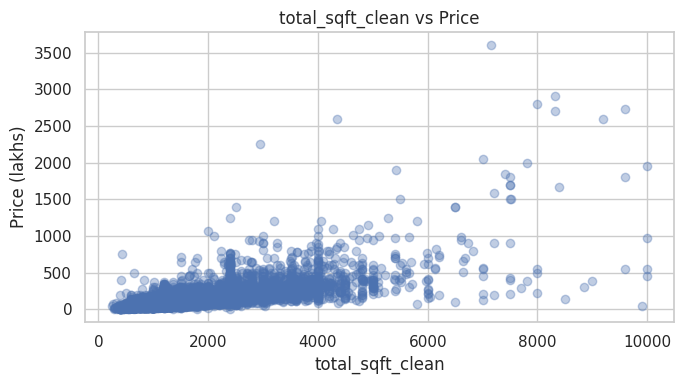

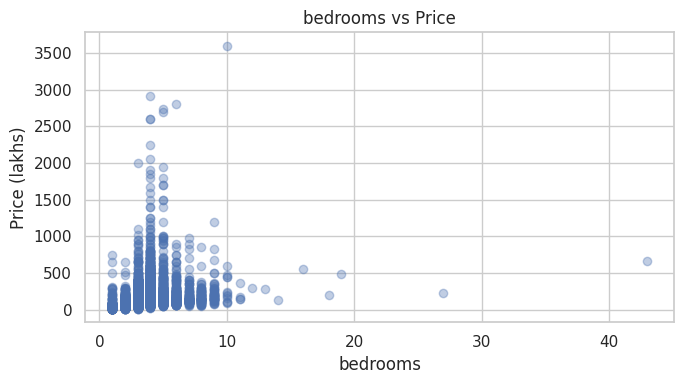

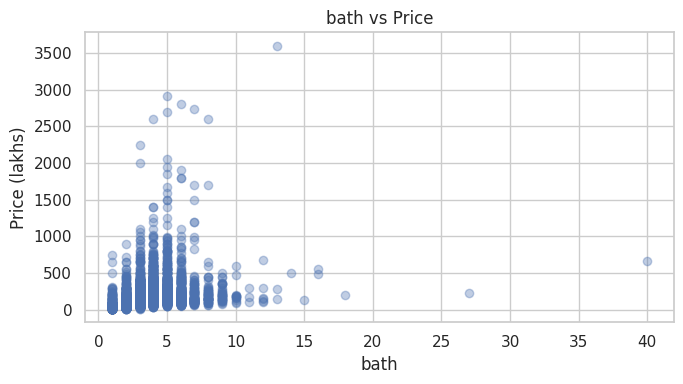

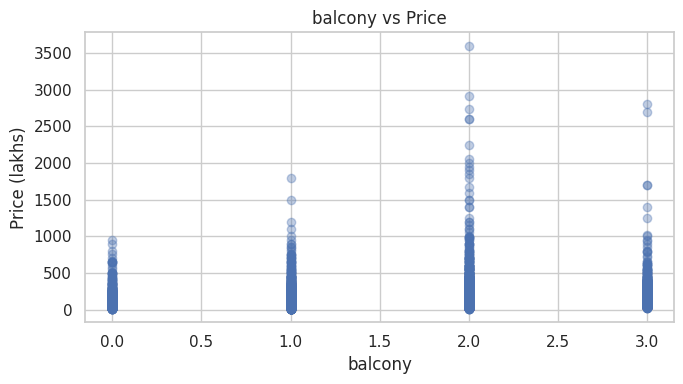

In [27]:
# Scatterplots of each feature against target
for feature in features:
    plt.figure(figsize=(7, 4))
    plt.scatter(df_model[feature], df_model[target], alpha=0.35)
    plt.xlabel(feature)
    plt.ylabel("Price (lakhs)")
    plt.title(f"{feature} vs Price")
    plt.tight_layout()
    plt.show()

,total_sqft_clean,bedrooms,bath,balcony,price
total_sqft_clean,NaN,NaN,NaN,NaN,NaN
bedrooms,NaN,NaN,NaN,NaN,NaN
bath,NaN,NaN,NaN,NaN,NaN
balcony,NaN,NaN,NaN,NaN,NaN
price,NaN,NaN,NaN,NaN,NaN


/usr/local/lib/python3.13/dist-packages/seaborn/matrix.py:202: RuntimeWarning: All-NaN slice encountered
  vmin = np.nanmin(calc_data)
/usr/local/lib/python3.13/dist-packages/seaborn/matrix.py:207: RuntimeWarning: All-NaN slice encountered
  vmax = np.nanmax(calc_data)


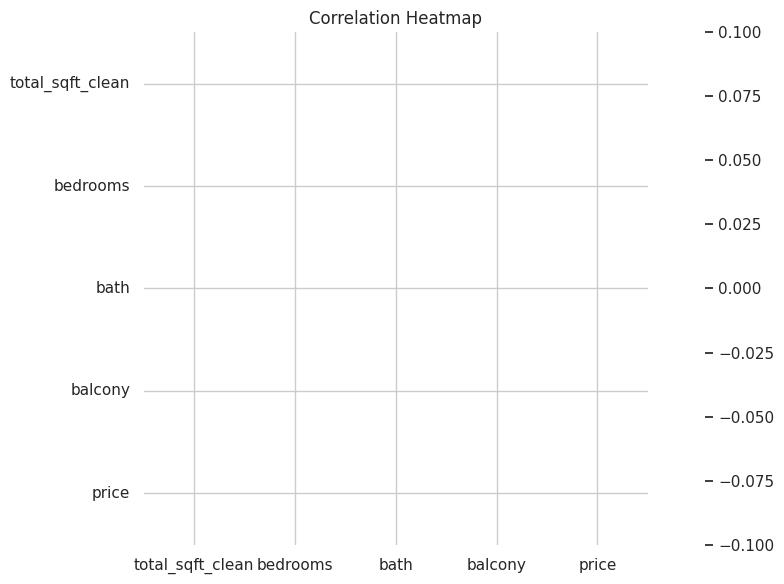

In [10]:
# Correlation matrix and heatmap
corr_matrix = df_model[features + [target]].corr()
display(corr_matrix.round(3))

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

### Correlation interpretation (complete after viewing your heatmap)
Describe which feature has the strongest positive/negative relationship with price. Also discuss correlations between predictor features as potential multicollinearity indicators. Correlation does not prove causation.

## 5. Manual Multiple Linear Regression (Two Features, 5–8 Observations)

For manual calculation, use **Area** and **Bedrooms** as the two predictors and select six rows. The calculations use the normal equation:
\[
\hat{\beta}=(X^TX)^{-1}X^Ty
\]
where the design matrix has a column of ones for the intercept.

In [28]:
manual_data = df_model[["total_sqft_clean", "bedrooms", "price"]].dropna().head(6).copy()
manual_data.columns = ["X1_Area_sqft", "X2_Bedrooms", "Y_Price_lakhs"]
display(manual_data)

,X1_Area_sqft,X2_Bedrooms,Y_Price_lakhs
0,1056.0,2.0,39.07
1,2600.0,4.0,120.00
2,1440.0,3.0,62.00
3,1521.0,3.0,95.00
4,1200.0,2.0,51.00
5,1170.0,2.0,38.00


In [29]:
# Design matrix X (ones column, X1, X2) and target vector y
X_manual = np.column_stack([
    np.ones(len(manual_data)),
    manual_data["X1_Area_sqft"].values,
    manual_data["X2_Bedrooms"].values
])
y_manual = manual_data["Y_Price_lakhs"].values

print("Design matrix X:")
display(pd.DataFrame(X_manual, columns=["1 (Intercept)", "X1 Area", "X2 Bedrooms"]))
print("Target vector y:")
display(pd.DataFrame(y_manual, columns=["Price"]))

Design matrix X:


,1 (Intercept),X1 Area,X2 Bedrooms
0,1.0,1056.0,2.0
1,1.0,2600.0,4.0
2,1.0,1440.0,3.0
3,1.0,1521.0,3.0
4,1.0,1200.0,2.0
5,1.0,1170.0,2.0


Target vector y:


,Price
0,39.07
1,120.00
2,62.00
3,95.00
4,51.00
5,38.00


In [30]:
# Calculate X transpose X and X transpose y
XtX = X_manual.T @ X_manual
Xty = X_manual.T @ y_manual

print("X^T X:")
display(pd.DataFrame(XtX))
print("X^T y:")
display(pd.DataFrame(Xty))

X^T X:


,0,1,2
0,6.0,8987.0,16.0
1,8987.0,15071077.0,26135.0
2,16.0,26135.0,46.0


X^T y:


,0
0,405.07
1,692692.92
2,1207.14


In [31]:
# Solve normal equations (least-squares solution)
manual_coefficients = np.linalg.lstsq(X_manual, y_manual, rcond=None)[0]
b0, b1, b2 = manual_coefficients

print(f"b0 (Intercept) = {b0:.6f}")
print(f"b1 (Area)      = {b1:.6f}")
print(f"b2 (Bedrooms)  = {b2:.6f}")
print(f"Manual equation: Price = {b0:.4f} + ({b1:.4f} × Area) + ({b2:.4f} × Bedrooms)")

b0 (Intercept) = -30.044187
b1 (Area)      = 0.016842
b2 (Bedrooms)  = 27.123266
Manual equation: Price = -30.0442 + (0.0168 × Area) + (27.1233 × Bedrooms)


In [32]:
print("Manual data shape:", manual_data.shape)
print("X_manual shape:", X_manual.shape)
print("y_manual shape:", y_manual.shape)

Manual data shape: (6, 3)
X_manual shape: (6, 3)
y_manual shape: (6,)


In [33]:
# Predict one observation from manual sample and calculate residual
manual_prediction = X_manual[0] @ manual_coefficients
manual_actual = y_manual[0]
manual_residual = manual_actual - manual_prediction

print("Selected observation:")
display(manual_data.iloc[[0]])
print(f"Predicted price: {manual_prediction:.4f} lakhs")
print(f"Actual price:    {manual_actual:.4f} lakhs")
print(f"Residual (Actual - Predicted): {manual_residual:.4f} lakhs")

Selected observation:


,X1_Area_sqft,X2_Bedrooms,Y_Price_lakhs
0,1056.0,2.0,39.07


Predicted price: 41.9879 lakhs
Actual price:    39.0700 lakhs
Residual (Actual - Predicted): -2.9179 lakhs


## 6. Train-Test Split

In [34]:
X = df_model[features]
y = df_model[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])
print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

Training records: 10194
Testing records: 2549
Training feature shape: (10194, 4)
Testing feature shape: (2549, 4)


## 7. Single-Feature Linear Regression Baseline

We use area as the single predictor for the baseline model. Both models use the same train/test split for a fair comparison.

In [35]:
X_single_train = X_train[["total_sqft_clean"]]
X_single_test = X_test[["total_sqft_clean"]]

single_model = LinearRegression()
single_model.fit(X_single_train, y_train)
single_pred = single_model.predict(X_single_test)

print("Single-feature intercept:", single_model.intercept_)
print("Single-feature coefficient:", single_model.coef_[0])
print(f"Equation: Price = {single_model.intercept_:.4f} + ({single_model.coef_[0]:.4f} × Area)")
print("Single-feature test R2:", r2_score(y_test, single_pred))

Single-feature intercept: -67.51966230819897
Single-feature coefficient: 0.11730491372751696
Equation: Price = -67.5197 + (0.1173 × Area)
Single-feature test R2: 0.5218812602923176


## 8. Multiple Linear Regression Model

In [36]:
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)
multiple_pred = multiple_model.predict(X_test)

print("Multiple model intercept:", multiple_model.intercept_)
coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": multiple_model.coef_
})
display(coefficients)

equation = f"Price = {multiple_model.intercept_:.4f}"
for feature, coef in zip(features, multiple_model.coef_):
    equation += f" + ({coef:.4f} × {feature})"
print("Multiple regression equation:")
print(equation)

Multiple model intercept: -79.99099746065642


,Feature,Coefficient
0,total_sqft_clean,0.106154
1,bedrooms,-3.684578
2,bath,19.169166
3,balcony,-7.328731


Multiple regression equation:
Price = -79.9910 + (0.1062 × total_sqft_clean) + (-3.6846 × bedrooms) + (19.1692 × bath) + (-7.3287 × balcony)


## 9. Verify Manual Calculation with Library Model

In [37]:
manual_library_model = LinearRegression()
manual_library_model.fit(manual_data[["X1_Area_sqft", "X2_Bedrooms"]], manual_data["Y_Price_lakhs"])

print("Manual calculation coefficients:", manual_coefficients)
print("Library intercept:", manual_library_model.intercept_)
print("Library coefficients:", manual_library_model.coef_)
print("\\nDifference (manual vs library):")
print("Intercept difference:", manual_coefficients[0] - manual_library_model.intercept_)
print("Coefficient differences:", manual_coefficients[1:] - manual_library_model.coef_)

Manual calculation coefficients: [-3.00441874e+01  1.68424237e-02  2.71232664e+01]
Library intercept: -30.044187390805902
Library coefficients: [1.68424237e-02 2.71232664e+01]
\nDifference (manual vs library):
Intercept difference: 3.197442310920451e-14
Coefficient differences: [-5.55111512e-17  1.06581410e-14]


## 10. Coefficient Interpretation

Interpret each coefficient as the predicted change in price (lakhs) for a one-unit increase in that feature, **holding other included features constant**. The intercept is the predicted price when all predictors are zero; that may not represent a realistic house. Coefficients depend on measurement units and do not establish causation.

In [38]:
# Standardized coefficients: scale predictors using training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

standardized_model = LinearRegression()
standardized_model.fit(X_train_scaled, y_train)

standardized_coefficients = pd.DataFrame({
    "Feature": features,
    "Standardized Coefficient": standardized_model.coef_
}).sort_values("Standardized Coefficient", key=lambda s: s.abs(), ascending=False)

display(standardized_coefficients)

,Feature,Standardized Coefficient
0,total_sqft_clean,93.342375
2,bath,25.521647
3,balcony,-5.919332
1,bedrooms,-4.772523


## 11. Predictions: Actual vs Predicted

In [39]:
prediction_table = pd.DataFrame({
    "Actual Price (lakhs)": y_test.values,
    "Predicted Price (lakhs)": multiple_pred
})
display(prediction_table.head(10))

,Actual Price (lakhs),Predicted Price (lakhs)
0,60.00,129.185039
1,31.48,59.357625
2,60.00,91.928968
3,84.00,76.873083
4,40.60,46.827333
5,56.00,68.911511
6,56.00,83.273162
7,32.72,42.903709
8,50.00,57.234539
9,65.00,93.429067


## 12. Regression Evaluation Metrics (Test Set)

In [40]:
def adjusted_r2(r2, n, p):
    if n <= p + 1:
        return np.nan
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

def evaluate_model(y_true, y_pred, number_of_features):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    adj_r2 = adjusted_r2(r2, len(y_true), number_of_features)
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2, "Adjusted R2": adj_r2}

single_metrics = evaluate_model(y_test, single_pred, 1)
multiple_metrics = evaluate_model(y_test, multiple_pred, len(features))

comparison = pd.DataFrame(
    [single_metrics, multiple_metrics],
    index=["Single-feature (Area)", "Multiple-feature"]
)
display(comparison.round(4))

,MAE,MSE,RMSE,R2,Adjusted R2
Single-feature (Area),45.3870,7873.5550,88.7331,0.5219,0.5217
Multiple-feature,42.9258,7931.9639,89.0616,0.5183,0.5176


### Metric interpretation
- **MAE:** average absolute prediction error in lakhs.
- **MSE:** average squared prediction error in lakhs squared.
- **RMSE:** error measure in target units (lakhs), penalizes larger errors more.
- **R²:** proportion of test target variation explained relative to a mean-based baseline; can be negative on test data.
- **Adjusted R²:** adjusts R² for the number of predictors.

## 13. Model Comparison and Predicted-vs-Actual Plot

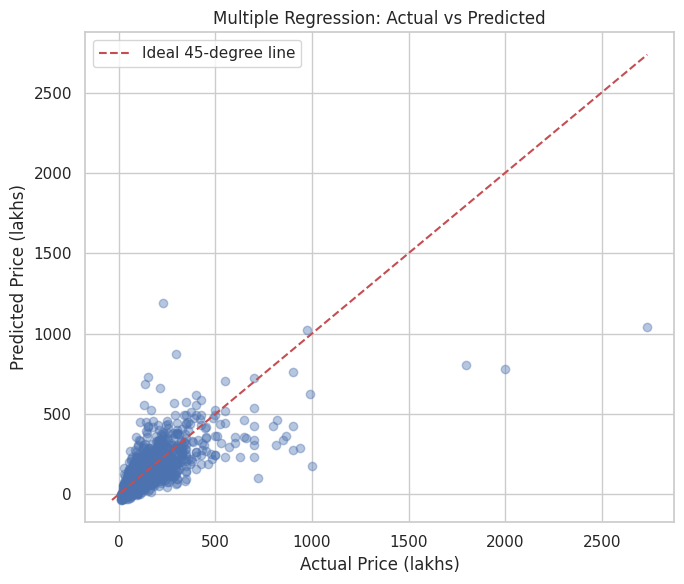

In [41]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, multiple_pred, alpha=0.4)
min_val = min(y_test.min(), multiple_pred.min())
max_val = max(y_test.max(), multiple_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], "r--", label="Ideal 45-degree line")
plt.xlabel("Actual Price (lakhs)")
plt.ylabel("Predicted Price (lakhs)")
plt.title("Multiple Regression: Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()

## 14. Residual Analysis

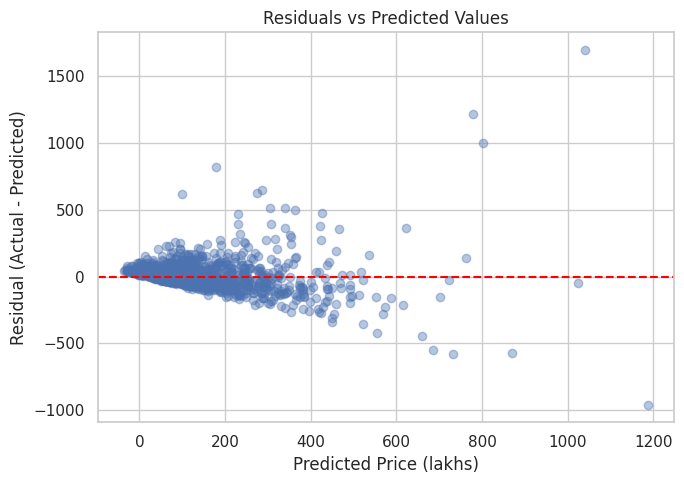

In [42]:
residuals = y_test - multiple_pred

plt.figure(figsize=(7, 5))
plt.scatter(multiple_pred, residuals, alpha=0.4)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Price (lakhs)")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residuals vs Predicted Values")
plt.tight_layout()
plt.show()

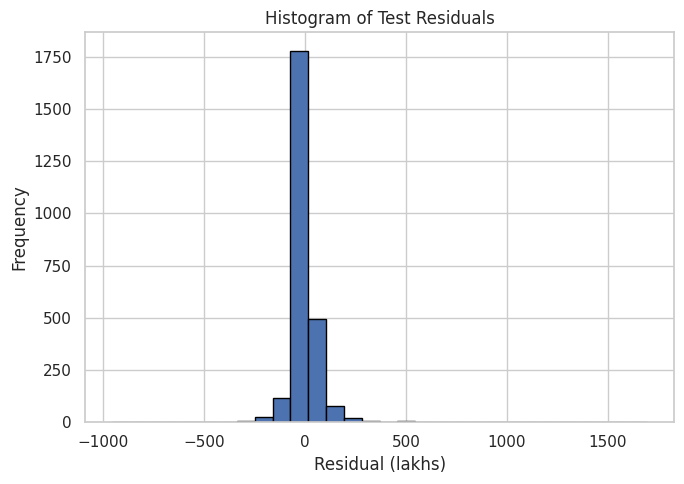

In [43]:
plt.figure(figsize=(7, 5))
plt.hist(residuals, bins=30, edgecolor="black")
plt.xlabel("Residual (lakhs)")
plt.ylabel("Frequency")
plt.title("Histogram of Test Residuals")
plt.tight_layout()
plt.show()

### Residual interpretation
Look for residuals scattered around zero without a clear pattern. A curve may suggest non-linearity; a funnel shape may suggest non-constant variance. The histogram should be roughly symmetric for approximate normality, although large datasets can still show departures. These plots are diagnostic, not proof that assumptions hold.

## 15. Multicollinearity Check: Correlation and VIF

In [44]:
# VIF calculated on selected predictors (not the target)
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame({
    "Feature": X_train.columns,
    "VIF": [variance_inflation_factor(X_train.values, i) for i in range(X_train.shape[1])]
})
display(vif_data)

,Feature,VIF
0,total_sqft_clean,1.387142
1,bedrooms,4.940066
2,bath,5.399592
3,balcony,1.062042


**VIF interpretation (rule of thumb):** VIF near 1 indicates little linear overlap with other predictors; values above about 5 may warrant investigation, and values above 10 are often considered high. Thresholds are guidelines, not automatic rules. If a feature has high VIF, investigate whether it is redundant and consider dropping or combining features.

## 16. Regression Assumptions

Discuss each assumption using your plots and checks:
1. **Linearity:** predictors have an approximately linear relationship with the target (inspect scatterplots and residual pattern).
2. **Independence of errors:** observations/errors should not be systematically dependent (consider the nature of the dataset).
3. **Constant variance (homoscedasticity):** residual spread should be roughly similar across fitted values (residual plot).
4. **Approximate normality of errors:** residual histogram should be roughly symmetric (mainly relevant for inference).
5. **No severe multicollinearity:** predictor variables should not have excessive linear overlap (correlation and VIF).

Write which assumptions seem reasonable and which appear doubtful for this dataset.

## 17. New House Price Prediction

In [45]:
# Example input values should be within the range of the training data.
new_house = pd.DataFrame([{
    "total_sqft_clean": 1500,
    "bedrooms": 3,
    "bath": 2,
    "balcony": 1
}])

new_house_prediction = multiple_model.predict(new_house)[0]
print("Input features:")
display(new_house)
print(f"Predicted price: {new_house_prediction:.2f} lakhs")

Input features:


,total_sqft_clean,bedrooms,bath,balcony
0,1500,3,2,1


Predicted price: 99.20 lakhs


## 18. Decision Log



| Decision | Reason |
|---|---|
| Dataset selected | Bengaluru house data provides numerical house attributes and continuous price target. |
| Features selected | Area, bedrooms, bathrooms, balconies are numeric and plausibly related to price. |
| `society` excluded | Large number of missing values; not used in selected numerical model. |
| Area conversion | Ranges converted to midpoint and recognized units converted to square feet. |
| Missing predictor values | Median imputation used; document columns and count affected. |
| Outlier handling | Area outside selected screening range removed; state this is a practical threshold. |
| Model comparison | Compare test metrics for single-feature and multiple-feature models. |
| Limitations | Location and other amenities omitted; linear model may miss nonlinear relationships and price differences. |

## 19. Conclusion

## Conclusion

In this activity, Multiple Linear Regression was implemented using the Bengaluru House Price dataset to estimate house prices based on numerical predictors. The selected predictors were total square footage, number of bedrooms, bathrooms, and balconies, with house price as the target variable.

Preprocessing was performed to handle missing values, convert total square footage values into numerical form, remove duplicate records, and filter unrealistic area values. Missing predictor values were handled using median imputation.

Manual regression calculations were performed using a small sample of observations by constructing the design matrix and estimating the regression coefficients. The manually calculated coefficients were verified using the Scikit-learn LinearRegression library, confirming the implementation of the regression method.

The single-feature regression model using square footage was compared with the multiple-feature regression model using square footage, bedrooms, bathrooms, and balconies. The **[single-feature/multiple-feature] model performed better on the test dataset**, with an R² score of **[value]**, compared with **[value]** for the other model. The evaluation metrics MAE, MSE, and RMSE were used to measure prediction errors, while R² and Adjusted R² were used to assess the model's explanatory performance.

Correlation analysis and VIF were used to examine relationships between predictors and identify possible multicollinearity. Residual plots and the residual histogram were analyzed to observe error patterns, distribution, and possible deviations from regression assumptions.

The model has certain limitations. It does not include important factors such as location, nearby amenities, property age, and construction quality. Outliers may affect regression coefficients and predictions. The model also assumes approximately linear relationships between predictors and house price, and predictions outside the range of the training data may be unreliable due to extrapolation.

Overall, this activity demonstrated the mathematical foundation, implementation, evaluation, and limitations of Multiple Linear Regression for house price estimation.
